In [1]:
import os
from pathlib import Path

import pandas as pd

In [2]:
data_dir = Path("/kaggle/input/datasets/mateuszbuda/lgg-mri-segmentation/kaggle_3m")
csv_path = data_dir / "data.csv"

In [3]:
dirs = [item for item in os.listdir(data_dir) if "TCGA" in item]
images_data = []

for dir_name in dirs:
    dir_images = os.listdir(data_dir / dir_name)
    
    for image_name in dir_images:
        if "mask" in image_name:
            continue
    
        masked_image_name = f"{image_name[:-4]}_mask.tif"
        images_data.append([image_name, masked_image_name])

images_df = pd.DataFrame(images_data, columns=["Image", "Mask"])
images_df.head()

,Image,Mask
0,TCGA_DU_7010_19860307_45.tif,TCGA_DU_7010_19860307_45_mask.tif
1,TCGA_DU_7010_19860307_57.tif,TCGA_DU_7010_19860307_57_mask.tif
2,TCGA_DU_7010_19860307_33.tif,TCGA_DU_7010_19860307_33_mask.tif
3,TCGA_DU_7010_19860307_27.tif,TCGA_DU_7010_19860307_27_mask.tif
4,TCGA_DU_7010_19860307_52.tif,TCGA_DU_7010_19860307_52_mask.tif


In [4]:
import cv2
import torch
from torch.utils.data import Dataset

In [5]:
class MRIDataset(Dataset):
    def __init__(self, path=data_dir):
        self.image_paths = []
        
        dirs = [item for item in os.listdir(data_dir) if "TCGA" in item]
        images_data = []
        
        for dir_name in dirs:
            dir_path = data_dir / dir_name
            dir_images = os.listdir(dir_path)
            
            for image_name in dir_images:
                if "mask" in image_name:
                    continue

                image_path = dir_path / image_name
                self.image_paths.append(image_path)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = str(self.image_paths[idx])
        masked_image_path = f"{image_path[:-4]}_mask.tif"

        image = torch.from_numpy(cv2.imread(image_path, cv2.COLOR_BGR2RGB)).float().permute(2,0,1) / 255
        mask  = torch.from_numpy(cv2.imread(masked_image_path, cv2.IMREAD_GRAYSCALE)).float()[None,:,:] / 255
        
        return image, mask

In [6]:
import matplotlib.pyplot as plt

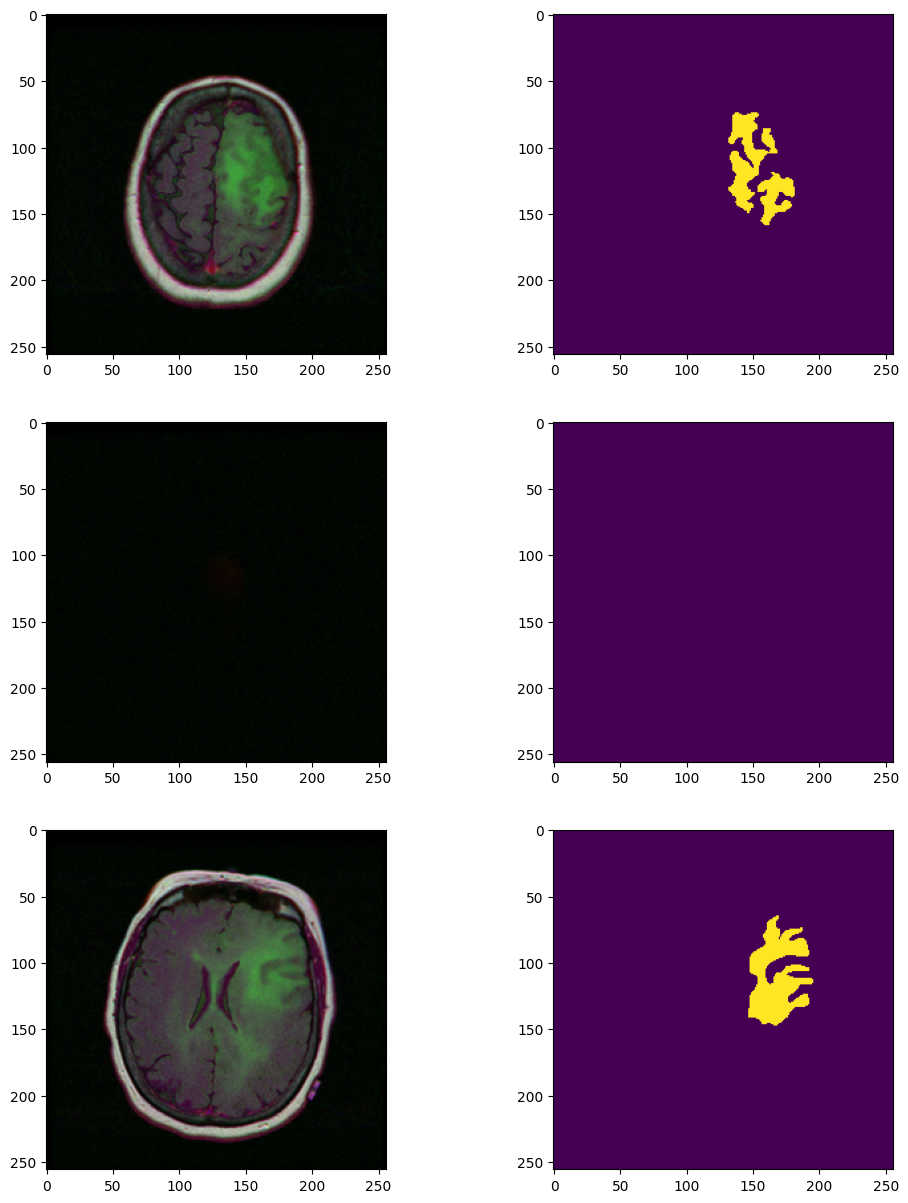

In [7]:
mri_dataset = MRIDataset()

nrows = 3
fig, axes = plt.subplots(nrows,2,figsize=(12,15))

for i in range(nrows):
    image, mask = mri_dataset[i]
    axes[i][0].imshow(image.permute(1,2,0))
    axes[i][1].imshow(mask.permute(1,2,0))

plt.show()